In [1]:
!pip -q install scikit-learn pandas matplotlib seaborn joblib
import os, zipfile, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (classification_report, f1_score, hamming_loss,
                             roc_auc_score, multilabel_confusion_matrix)
import joblib
warnings.filterwarnings("ignore")
RANDOM_STATE = 42

In [2]:
uploaded = files.upload()  # Choose jigsaw-toxic-comment-classification-challenge.zip
outer_zip = next((name for name in uploaded if name.lower().endswith(".zip")), None)
if outer_zip is None:
    raise ValueError("Please upload the Jigsaw challenge .zip file.")
extract_dir = "/content/jigsaw_data"
os.makedirs(extract_dir, exist_ok=True)
with zipfile.ZipFile(outer_zip) as z:
    z.extractall(extract_dir)

# The challenge archive has train.csv.zip, test.csv.zip, etc. Extract nested archives.
for nested_zip in glob.glob(os.path.join(extract_dir, "*.zip")):
    with zipfile.ZipFile(nested_zip) as z:
        z.extractall(extract_dir)

print("Extracted files:")
print("\n".join(sorted(os.listdir(extract_dir))))

Saving jigsaw-toxic-comment-classification-challenge.zip to jigsaw-toxic-comment-classification-challenge.zip
Extracted files:
sample_submission.csv
sample_submission.csv.zip
test.csv
test.csv.zip
test_labels.csv
test_labels.csv.zip
train.csv
train.csv.zip


In [3]:
train_path = os.path.join(extract_dir, "train.csv")
if not os.path.exists(train_path):
    matches = glob.glob(os.path.join(extract_dir, "**", "train.csv"), recursive=True)
    if not matches:
        raise FileNotFoundError("train.csv was not found after extraction.")
    train_path = matches[0]

df = pd.read_csv(train_path)
LABELS = ["toxic", "severe_toxic", "obscene", "threat", "insult", "identity_hate"]
required = {"comment_text", *LABELS}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Missing expected columns: {missing}. Check that this is the Jigsaw training file.")

print("Dataset shape:", df.shape)
display(df.head())
print("\nMissing values:")
display(df[["comment_text"] + LABELS].isna().sum().to_frame("missing_count"))
print("\nLabel counts:")
display(df[LABELS].sum().sort_values(ascending=False).to_frame("positive_examples"))

Dataset shape: (159571, 8)


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0



Missing values:


,missing_count
comment_text,0
toxic,0
severe_toxic,0
obscene,0
threat,0
insult,0
identity_hate,0



Label counts:


,positive_examples
toxic,15294
obscene,8449
insult,7877
severe_toxic,1595
identity_hate,1405
threat,478


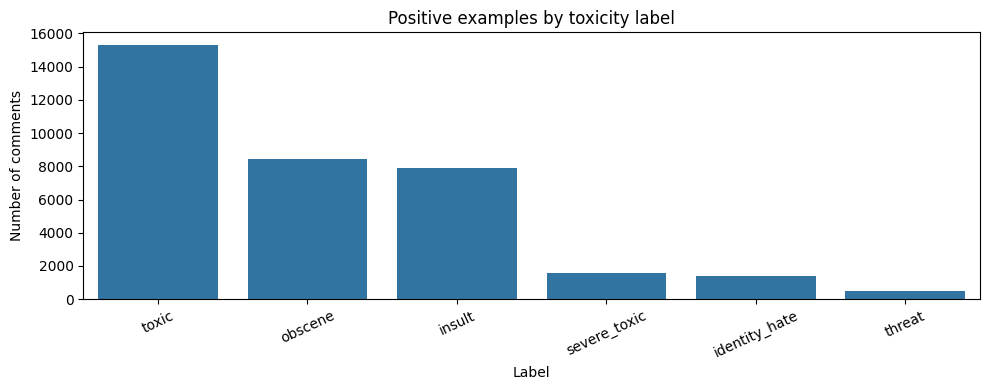

Empty comments: 0
Comments with at least one label: 16225


In [4]:
label_counts = df[LABELS].sum().sort_values(ascending=False)
plt.figure(figsize=(10, 4))
sns.barplot(x=label_counts.index, y=label_counts.values)
plt.title("Positive examples by toxicity label")
plt.ylabel("Number of comments")
plt.xlabel("Label")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

df["comment_text"] = df["comment_text"].fillna("").astype(str)
print("Empty comments:", (df["comment_text"].str.strip() == "").sum())
print("Comments with at least one label:", int((df[LABELS].sum(axis=1) > 0).sum()))

In [5]:
X = df["comment_text"]
y = df[LABELS].astype(int)

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Training rows:", len(X_train), "| Validation rows:", len(X_val))

Training rows: 127656 | Validation rows: 31915


In [6]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=150_000,
        ngram_range=(1, 2),
        min_df=2,
        strip_accents="unicode",
        sublinear_tf=True,
        dtype=np.float32
    )),
    ("classifier", OneVsRestClassifier(
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            solver="liblinear",
            random_state=RANDOM_STATE
        ),
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)
print("Training complete.")

Training complete.


In [7]:
y_prob = model.predict_proba(X_val)
y_pred = (y_prob >= 0.5).astype(int)

print("Micro F1:", round(f1_score(y_val, y_pred, average="micro", zero_division=0), 4))
print("Macro F1:", round(f1_score(y_val, y_pred, average="macro", zero_division=0), 4))
print("Weighted F1:", round(f1_score(y_val, y_pred, average="weighted", zero_division=0), 4))
print("Hamming loss:", round(hamming_loss(y_val, y_pred), 4))
try:
    print("Macro ROC-AUC:", round(roc_auc_score(y_val, y_prob, average="macro"), 4))
except ValueError as e:
    print("ROC-AUC unavailable:", e)

print("\nPer-label classification report:")
print(classification_report(y_val, y_pred, target_names=LABELS, zero_division=0))

Micro F1: 0.699
Macro F1: 0.5851
Weighted F1: 0.7153
Hamming loss: 0.027
Macro ROC-AUC: 0.981

Per-label classification report:
               precision    recall  f1-score   support

        toxic       0.66      0.85      0.74      3056
 severe_toxic       0.30      0.81      0.44       321
      obscene       0.73      0.87      0.79      1715
       threat       0.30      0.76      0.43        74
       insult       0.60      0.86      0.70      1614
identity_hate       0.28      0.71      0.40       294

    micro avg       0.59      0.85      0.70      7074
    macro avg       0.48      0.81      0.59      7074
 weighted avg       0.63      0.85      0.72      7074
  samples avg       0.06      0.08      0.07      7074



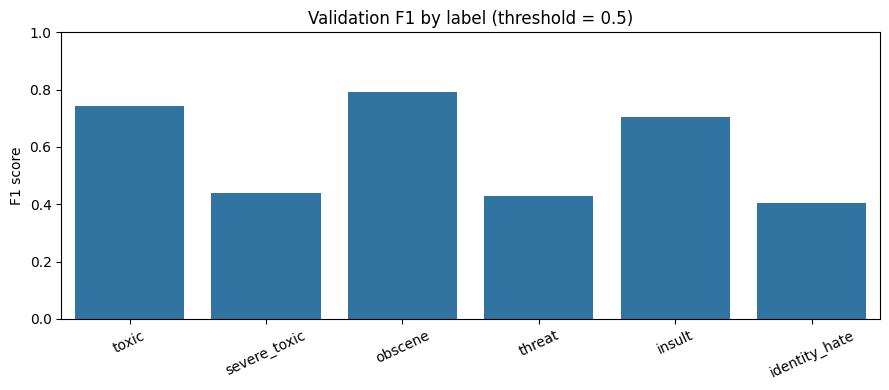

In [8]:
per_label_f1 = f1_score(y_val, y_pred, average=None, zero_division=0)
plt.figure(figsize=(9, 4))
sns.barplot(x=LABELS, y=per_label_f1)
plt.ylim(0, 1)
plt.ylabel("F1 score")
plt.title("Validation F1 by label (threshold = 0.5)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [9]:
def classify_comment(comment, threshold=0.5):
    probabilities = model.predict_proba([str(comment)])[0]
    result = pd.DataFrame({
        "label": LABELS,
        "probability": probabilities,
        "predicted_at_threshold": probabilities >= threshold
    }).sort_values("probability", ascending=False)
    return result.reset_index(drop=True)

examples = [
    "Thank you for explaining your point. I appreciate the discussion.",
    "You are an idiot and nobody wants you here."
]
for comment in examples:
    print("\nComment:", comment)
    display(classify_comment(comment))


Comment: Thank you for explaining your point. I appreciate the discussion.


,label,probability,predicted_at_threshold
0,identity_hate,0.025188,False
1,obscene,0.025102,False
2,insult,0.024581,False
3,toxic,0.017791,False
4,severe_toxic,0.013432,False
5,threat,0.008888,False



Comment: You are an idiot and nobody wants you here.


,label,probability,predicted_at_threshold
0,insult,0.999267,True
1,toxic,0.998389,True
2,obscene,0.939361,True
3,severe_toxic,0.368133,False
4,identity_hate,0.311768,False
5,threat,0.025918,False


In [10]:
model_path = "/content/toxic_comment_classifier.joblib"
joblib.dump({"model": model, "labels": LABELS}, model_path)
print("Saved:", model_path)
files.download(model_path)

Saved: /content/toxic_comment_classifier.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:

import joblib
import pandas as pd

# Upload the downloaded trained model
from google.colab import files
uploaded = files.upload()

model_file = "toxic_comment_classifier.joblib"

# Load the saved model
saved = joblib.load(model_file)
model = saved["model"]
labels = saved["labels"]

# Test with a new comment
comment = ["Thank you for your helpful explanation."]

probabilities = model.predict_proba(comment)[0]

results = pd.DataFrame({
    "Label": labels,
    "Probability": probabilities,
    "Prediction": probabilities >= 0.5
})

display(results)


Saving toxic_comment_classifier.joblib to toxic_comment_classifier (1).joblib


,Label,Probability,Prediction
0,toxic,0.027028,False
1,severe_toxic,0.009513,False
2,obscene,0.023669,False
3,threat,0.019980,False
4,insult,0.059543,False
5,identity_hate,0.014216,False
